**Data Analysis Sheet 01**

**Dataset 1: Pakistani E-Commerce Data**

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_style('whitegrid')

df_ecom = pd.read_csv('pakistani_ecommerce_dataset.csv')
print(df_ecom.head())

  user_id  gender age_group       city product_category    payment_method  \
0    U001    Male     25-34  Islamabad       Home Decor          JazzCash   
1    U002  Female     25-34     Lahore      Electronics         EasyPaisa   
2    U003  Female     25-34     Lahore            Books        Debit Card   
3    U004  Female     18-24     Lahore       Home Decor  Cash on Delivery   
4    U005  Female     35-44     Lahore       Home Decor         EasyPaisa   

   order_value order_status  
0      1899.62      Pending  
1      1592.21    Cancelled  
2      3851.78    Cancelled  
3      1774.12      Pending  
4      3611.28    Cancelled  


In [2]:
popular_category = df_ecom['product_category'].value_counts()
print(popular_category)

product_category
Home Decor     30
Clothing       22
Beauty         19
Electronics    18
Books          11
Name: count, dtype: int64


Q1: Home Decor is the most popular product category, with 30 out of 100 orders.

In [3]:
aov_overall = df_ecom['order_value'].mean()
aov_by_status = df_ecom.groupby('order_status')['order_value'].mean()

print(f'Overall Average Order Value: PKR {aov_overall:.2f}')
print('\nAverage Order Value by Status:\n', aov_by_status.round(2))

Overall Average Order Value: PKR 2832.15

Average Order Value by Status:
 order_status
Cancelled    3172.96
Delivered    2967.20
Pending      2452.05
Name: order_value, dtype: float64


Q2: The average order value is PKR 2,832.15.

In [4]:
orders_by_city = df_ecom['city'].value_counts()
print(orders_by_city)

city
Karachi       24
Islamabad     21
Rawalpindi    20
Lahore        18
Faisalabad    17
Name: count, dtype: int64


Q3: Karachi has the highest number of orders, 24 in total.

In [5]:
payment_counts = df_ecom['payment_method'].value_counts()
print(payment_counts)

payment_method
Cash on Delivery    29
JazzCash            27
EasyPaisa           23
Debit Card          21
Name: count, dtype: int64


Q4: Cash on Delivery is the most used payment method, with 29 orders.

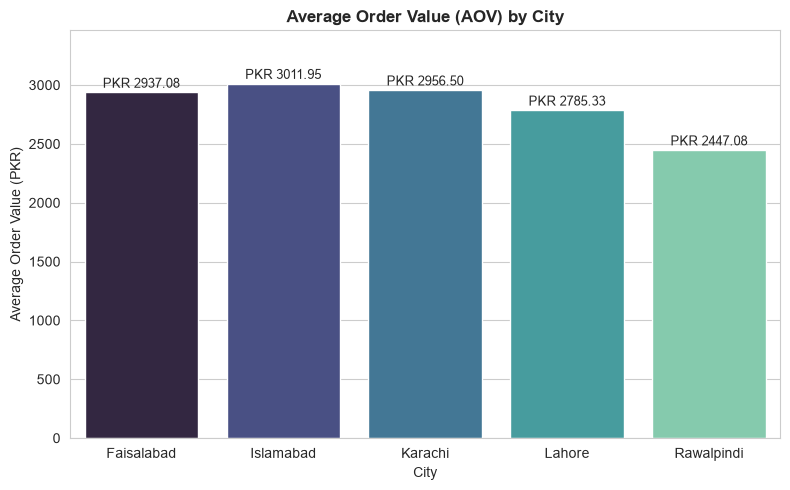

In [6]:
city_aov = df_ecom.groupby('city')['order_value'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=city_aov, x='city', y='order_value', hue='city', palette='mako', legend=False)

plt.title('Average Order Value (AOV) by City', fontsize=12, fontweight='bold')
plt.xlabel('City', fontsize=10)
plt.ylabel('Average Order Value (PKR)', fontsize=10)

for i, row in city_aov.iterrows():
    plt.text(
        i,
        row['order_value'] + 40,
        f"PKR {row['order_value']:.2f}",
        ha='center',
        fontsize=9,
    )

plt.ylim(0, city_aov['order_value'].max() * 1.15)
plt.tight_layout()
plt.show()

Q5: Islamabad has the highest average order value (PKR 3,011.95) and Rawalpindi has the lowest (PKR 2,447.08).

Dataset 2: Student Lifestyle & Study Habits

In [7]:
df_lifestyle = pd.read_csv('student_lifestyle_dataset.csv')
print(df_lifestyle.head())

  student_id  gender  study_hours  sleep_hours  screen_time  internet_usage  \
0       S001  Female          7.0          7.1          2.7             9.3   
1       S002  Female          4.9          6.9          2.9             1.0   
2       S003  Female          5.9          8.9          5.3             5.2   
3       S004  Female          3.2          4.2          1.8             5.2   
4       S005    Male          1.8          5.0          2.5             6.1   

   daily_transport_cost  
0                 102.0  
1                 284.0  
2                 123.0  
3                  73.0  
4                 202.0  


In [8]:
avg_study_hours = df_lifestyle['study_hours'].mean()
print(f'Average Study Hours: {avg_study_hours:.2f} hours')

Average Study Hours: 4.40 hours


Q1 Answer: Students in this dataset study an average of 4.40 hours (4.403 hours) per day.

In [9]:
sleep_by_gender = df_lifestyle.groupby('gender')['sleep_hours'].mean()
print(sleep_by_gender.round(2))

gender
Female    6.80
Male      6.39
Name: sleep_hours, dtype: float64


Q2: Females sleep more on average, 6.80 hours compared to 6.39 hours for males.

Pearson Correlation (r): 0.0524


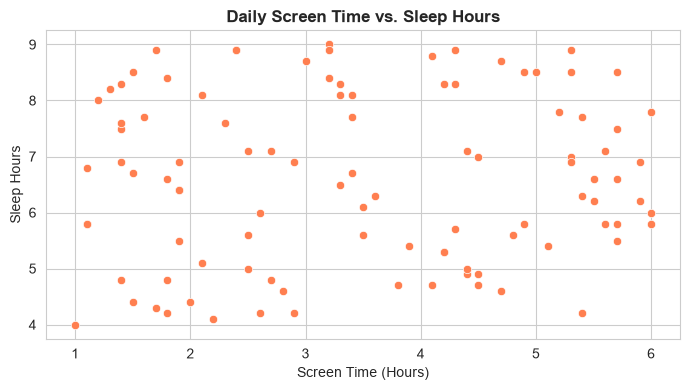

In [10]:
correlation = df_lifestyle['screen_time'].corr(df_lifestyle['sleep_hours'])
print(f'Pearson Correlation (r): {correlation:.4f}')

plt.figure(figsize=(7, 4))
sns.scatterplot(data=df_lifestyle, x='screen_time', y='sleep_hours', color='coral')
plt.title('Daily Screen Time vs. Sleep Hours', fontsize=12, fontweight='bold')
plt.xlabel('Screen Time (Hours)', fontsize=10)
plt.ylabel('Sleep Hours', fontsize=10)
plt.tight_layout()
plt.show()

Q3: There is no clear relationship between screen time and sleep hours. The correlation is 0.05, which is very close to zero.

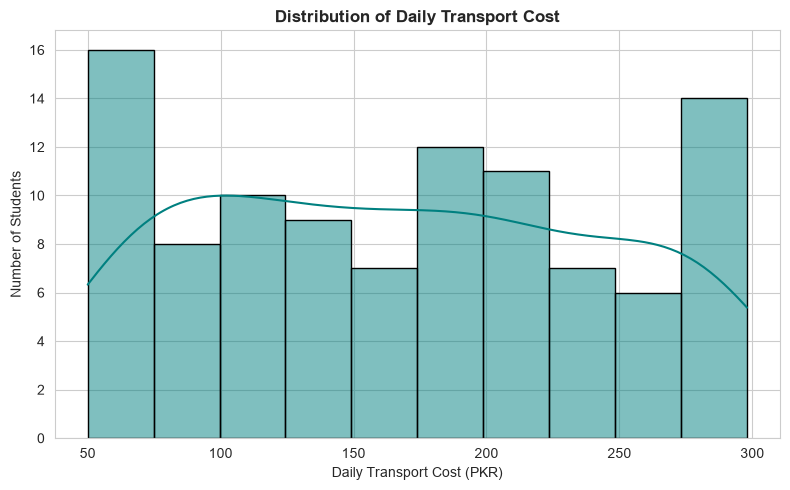

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(
    df_lifestyle['daily_transport_cost'],
    bins=10,
    kde=True,
    color='teal',
    edgecolor='black',
)

plt.title('Distribution of Daily Transport Cost', fontsize=12, fontweight='bold')
plt.xlabel('Daily Transport Cost (PKR)', fontsize=10)
plt.ylabel('Number of Students', fontsize=10)
plt.tight_layout()
plt.show()

Q4: Daily transport cost ranges from PKR 50 to PKR 298, with an average of about PKR 168. The costs are spread fairly evenly across the range.

   gender  internet_usage
0  Female            5.32
1    Male            6.00


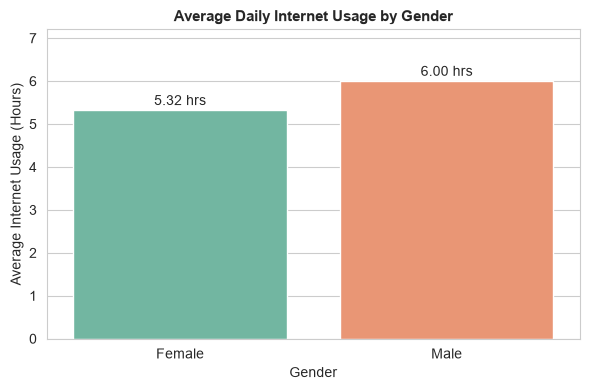

In [12]:
internet_by_gender = df_lifestyle.groupby('gender')['internet_usage'].mean().reset_index()
print(internet_by_gender.round(2))

plt.figure(figsize=(6, 4))
sns.barplot(data=internet_by_gender, x='gender', y='internet_usage', hue='gender', palette='Set2', legend=False)
plt.title('Average Daily Internet Usage by Gender', fontsize=11, fontweight='bold')
plt.xlabel('Gender', fontsize=10)
plt.ylabel('Average Internet Usage (Hours)', fontsize=10)

for i, row in internet_by_gender.iterrows():
    plt.text(
        i,
        row['internet_usage'] + 0.12,
        f"{row['internet_usage']:.2f} hrs",
        ha='center',
    )

plt.ylim(0, internet_by_gender['internet_usage'].max() * 1.2)
plt.tight_layout()
plt.show()

Q5: Males use more internet on average, 6.00 hours per day compared to 5.32 hours for females.